# Import Packages and install environment

Required: xarray, cfgrib, eccodes, numpy, pandas, matplotlib.
Install once with: conda install -c conda-forge cfgrib eccodes

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

By default (`SAVE = False`), the notebook only shows the figures and tables, so the files in `results/` are not changed.
Set `SAVE = True` to save them in `results/storm/` -> this overwrites the files there.

In [ ]:
SAVE = False   # True = save the figures and tables in results/storm/ (overwrites the files there)

result_dir = Path('../results/storm')

if SAVE:
    result_dir.mkdir(parents=True, exist_ok=True)

# Cell 1: load the storms
Load the ten GRIB storms around the target location, including `1997_LINDA.grib`. The BBOX is centred on 9°15'35.80" N, 105°57'23.90" E with a configurable half-width of 0.5 degrees.

Known GRIB variables are loaded directly: `swh` = HS, `pp1d` = peak wave period, `mwp` = mean wave period (Tm0), `mwd` = mean wave direction, and `10u`/`10v` = 10 m wind components.

In [ ]:

data_dir = Path('../data/data_storm')

storm_files = [
    r'1956_UNNAMED.grib', r'1962_LUCY.grib', r'1964_JOAN.grib',
    r'1964_UNNAMED.grib', r'1973_THELMA.grib', r'1992_ANGELA.grib',
    r'1996_ERNIE.grib', r'2006_DURIAN.grib', r'2018_TORAJI.grib'
]

# Target location: 9Ã‚Â°15'35.80" N, 105Ã‚Â°57'23.90" E.
target_lat = 9 + 15 / 60 + 35.80 / 3600
target_lon = 105 + 57 / 60 + 23.90 / 3600
bbox_half_size = 0.5
bbox = {
    'lat_min': target_lat - bbox_half_size, 'lat_max': target_lat + bbox_half_size,
    'lon_min': target_lon - bbox_half_size, 'lon_max': target_lon + bbox_half_size
}
window_hours = 6

try:
    import cfgrib  # noqa: F401
    assert cfgrib is not None
except ImportError as error:
    raise ImportError(
        'cfgrib/eccodes is required. Install with: '
        'conda install -c conda-forge cfgrib eccodes'
    ) from error

storm_files = [data_dir / path for path in storm_files if (data_dir / path).exists()]
if not storm_files:
    raise FileNotFoundError('No GRIB files found in the data directory.')


def open_grib_variable(path, short_name, required=False):
    """Open one known GRIB variable directly; no alias search is used."""
    try:
        dataset = xr.open_dataset(
            path, engine='cfgrib',
            backend_kwargs={
                'filter_by_keys': {'shortName': short_name},
                'indexpath': ''
            }
        )
        return dataset[list(dataset.data_vars)[0]]
    except Exception:
        if required:
            raise
        return None


def time_dimension(variable):
    for name in ('time', 'valid_time'):
        if name in variable.dims:
            return name
    return None


def time_axis(variable):
    dimension = time_dimension(variable)
    if dimension is None:
        return pd.DatetimeIndex([])
    if 'valid_time' in variable.coords and variable.sizes[dimension] == variable.valid_time.size:
        return pd.to_datetime(variable.valid_time.values)
    return pd.to_datetime(variable[dimension].values)


def spatial_mean(variable):
    dimension = time_dimension(variable)
    spatial_dimensions = [name for name in variable.dims if name != dimension]
    return variable.mean(dim=spatial_dimensions, skipna=True)


def finite_values(variable):
    if variable is None:
        return np.array([], dtype=float)
    values = np.asarray(variable.values if hasattr(variable, 'values') else variable, dtype=float).ravel()
    return values[np.isfinite(values)]


def vector_mean(degrees):
    values = finite_values(degrees)
    if not len(values):
        return np.nan
    radians = np.deg2rad(values)
    return float(np.rad2deg(np.arctan2(np.mean(np.sin(radians)), np.mean(np.cos(radians)))) % 360)


def value_or_nan(values, reducer):
    values = finite_values(values)
    return float(reducer(values)) if len(values) else np.nan


def styled_table(table, caption):
    return (
        table.style
        .format(precision=3, na_rep='n/a')
        .set_caption(caption)
        .set_table_styles([
            {'selector': 'caption', 'props': [('font-size', '16px'), ('font-weight', 'bold'), ('text-align', 'left')]},
            {'selector': 'th', 'props': [('background-color', '#1f4e5f'), ('color', 'white'), ('text-align', 'center')]},
            {'selector': 'td', 'props': [('padding', '5px 9px'), ('text-align', 'right')]},
            {'selector': 'tr:nth-child(even)', 'props': [('background-color', '#eef5f7')]}
        ])
    )


storms = {}
for path in storm_files:
    variables = {
        'hs_m': open_grib_variable(path, 'swh', required=True),
        'tp_s': open_grib_variable(path, 'pp1d'),
        'tm0_s': open_grib_variable(path, 'mwp'),
        'wave_dir_deg': open_grib_variable(path, 'mwd'),
        'u10_ms': open_grib_variable(path, '10u'),
        'v10_ms': open_grib_variable(path, '10v')
    }
    selected = {}
    for name, variable in variables.items():
        if variable is None or not {'latitude', 'longitude'} <= set(variable.coords):
            continue
        mask = (
            (variable.latitude >= bbox['lat_min']) & (variable.latitude <= bbox['lat_max']) &
            (variable.longitude >= bbox['lon_min']) & (variable.longitude <= bbox['lon_max'])
        )
        clipped = variable.where(mask, drop=True)
        if len(finite_values(clipped)):
            selected[name] = clipped
    if 'hs_m' not in selected:
        raise ValueError(f'No HS points found inside the BBOX for {path.name}.')
    selected['wind_speed_ms'] = np.hypot(selected['u10_ms'], selected['v10_ms'])
    storms[path.stem] = selected

print(f"Loaded {len(storms)} storms: {', '.join(storms)}")
print(f'BBOX: {bbox}')

Loaded 9 storms: 1956_UNNAMED, 1962_LUCY, 1964_JOAN, 1964_UNNAMED, 1973_THELMA, 1992_ANGELA, 1996_ERNIE, 2006_DURIAN, 2018_TORAJI
BBOX: {'lat_min': 8.759944444444445, 'lat_max': 9.759944444444445, 'lon_min': 105.45663888888889, 'lon_max': 106.45663888888889}


In [ ]:
# Add the 1997 LINDA storm to the same ERA5 analysis set
linda_path = data_dir / '1997_LINDA.grib'
if linda_path.exists():
    linda_variables = {
        'hs_m': open_grib_variable(linda_path, 'swh', required=True),
        'tp_s': open_grib_variable(linda_path, 'pp1d'),
        'tm0_s': open_grib_variable(linda_path, 'mwp'),
        'wave_dir_deg': open_grib_variable(linda_path, 'mwd'),
        'u10_ms': open_grib_variable(linda_path, '10u'),
        'v10_ms': open_grib_variable(linda_path, '10v')
    }
    linda_selected = {}
    for name, variable in linda_variables.items():
        if variable is None or not {'latitude', 'longitude'} <= set(variable.coords):
            continue
        linda_mask = (
            (variable.latitude >= bbox['lat_min']) & (variable.latitude <= bbox['lat_max']) &
            (variable.longitude >= bbox['lon_min']) & (variable.longitude <= bbox['lon_max'])
        )
        clipped = variable.where(linda_mask, drop=True)
        if len(finite_values(clipped)):
            linda_selected[name] = clipped
    linda_selected['wind_speed_ms'] = np.hypot(linda_selected['u10_ms'], linda_selected['v10_ms'])
    storms['1997_LINDA'] = linda_selected
    print('Added 1997_LINDA to the storm set.')

Added 1997_LINDA to the storm set.


# Cell 2: analyse and plot each storm
For every storm, the notebook finds the maximum spatially averaged HS and calculates a six-hour window around that peak. It also checks whether the spatial mean hides a stronger local grid-cell peak by reporting `point_max_hs`, the point-to-mean ratio, the time step and wind at the spatial-mean HS peak.

The six-hour spatial-mean condition is the realistic Delft3D input. The point maximum is retained as a short-duration plausibility and extreme-case check. A one-hour time step is sufficient to resolve the available historical peaks, but the BBOX and grid-cell location still influence the result.

The cell displays one plot per storm with:

- significant wave height, peak period and mean wave period
- wave direction
- wind components and wind speed

It also displays a formatted Delft3D input table with HS, TP, Tm0, mean wave direction, `u10`, `v10`, wind speed, `point_max_hs` and the diagnostic values.

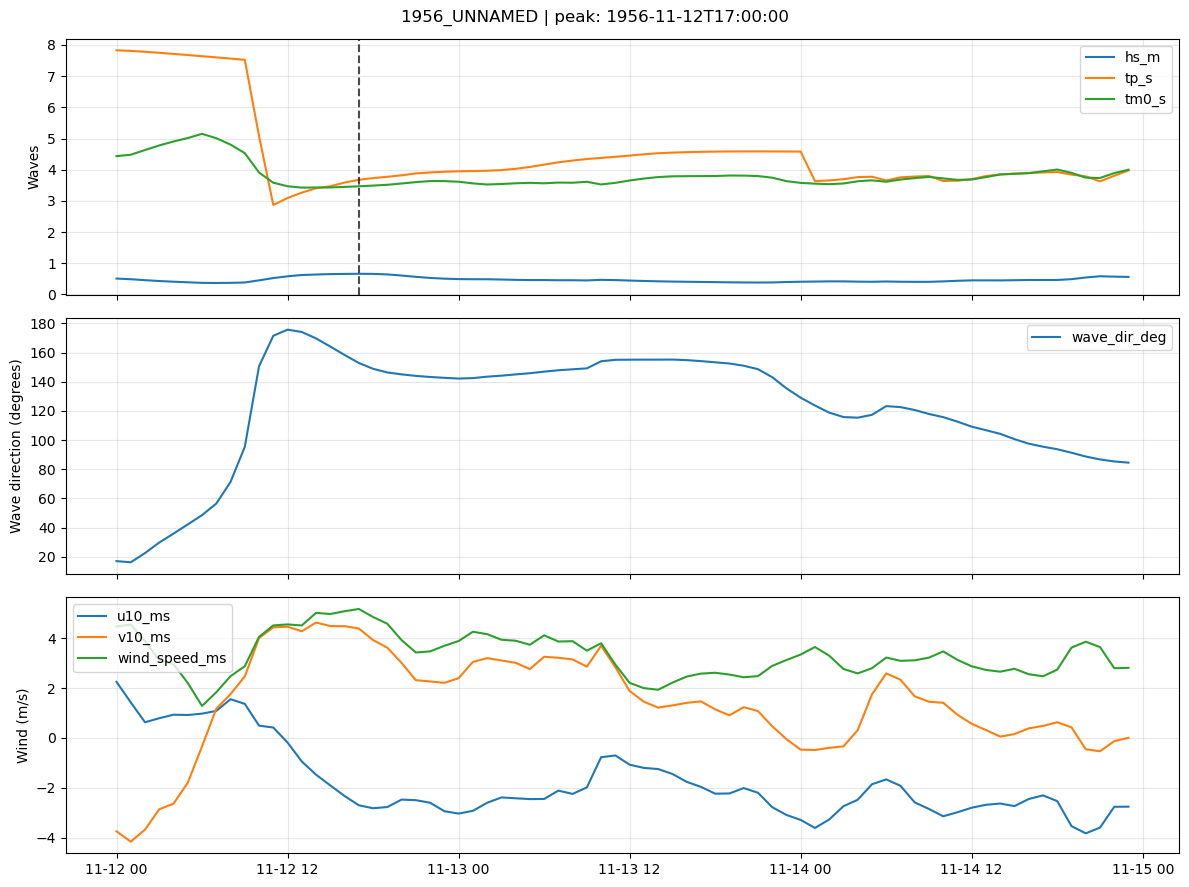

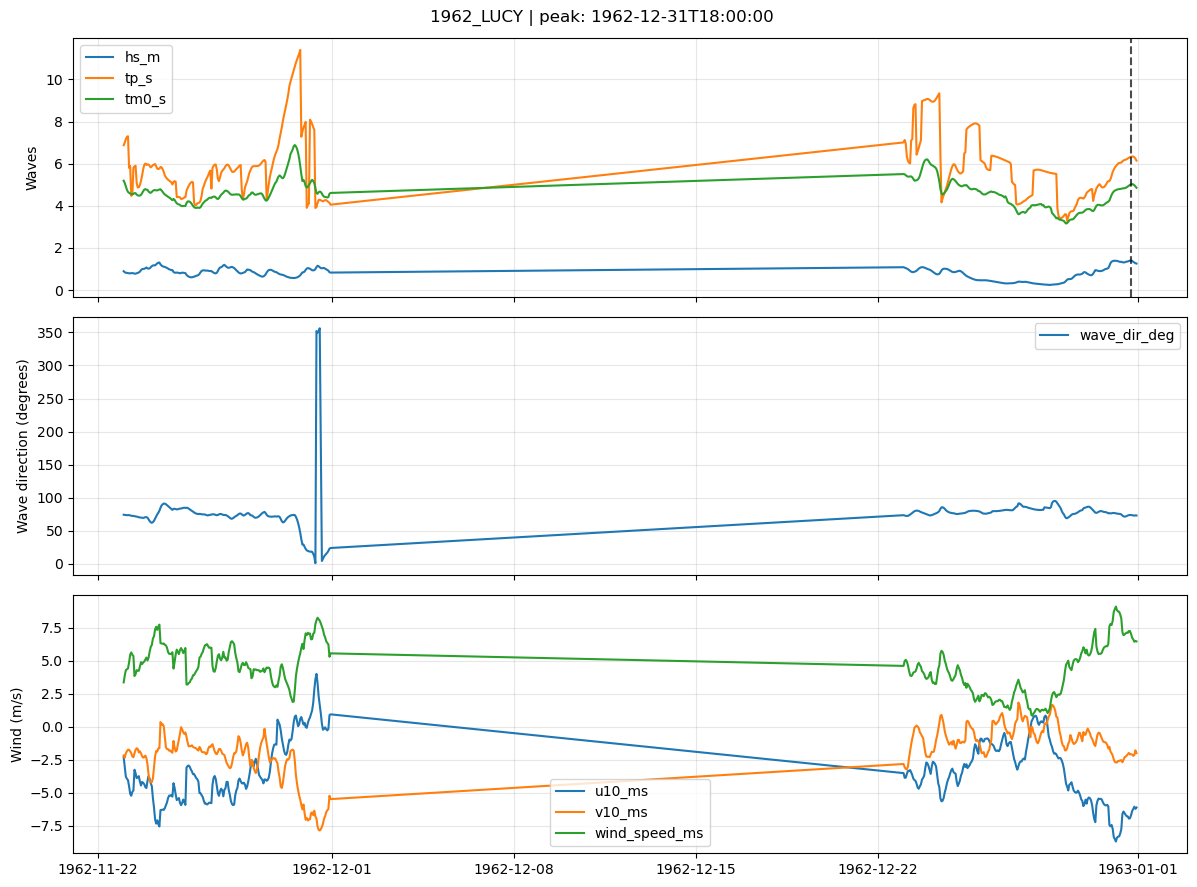

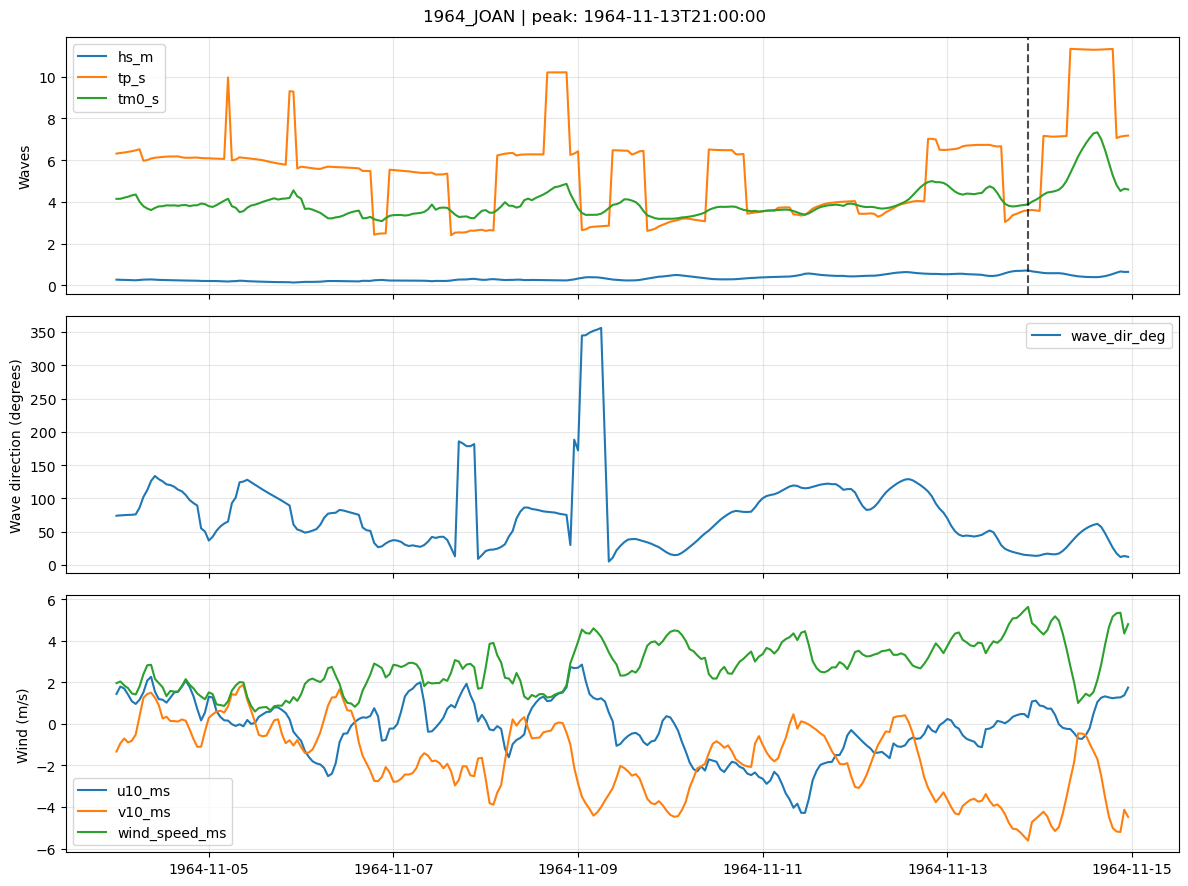

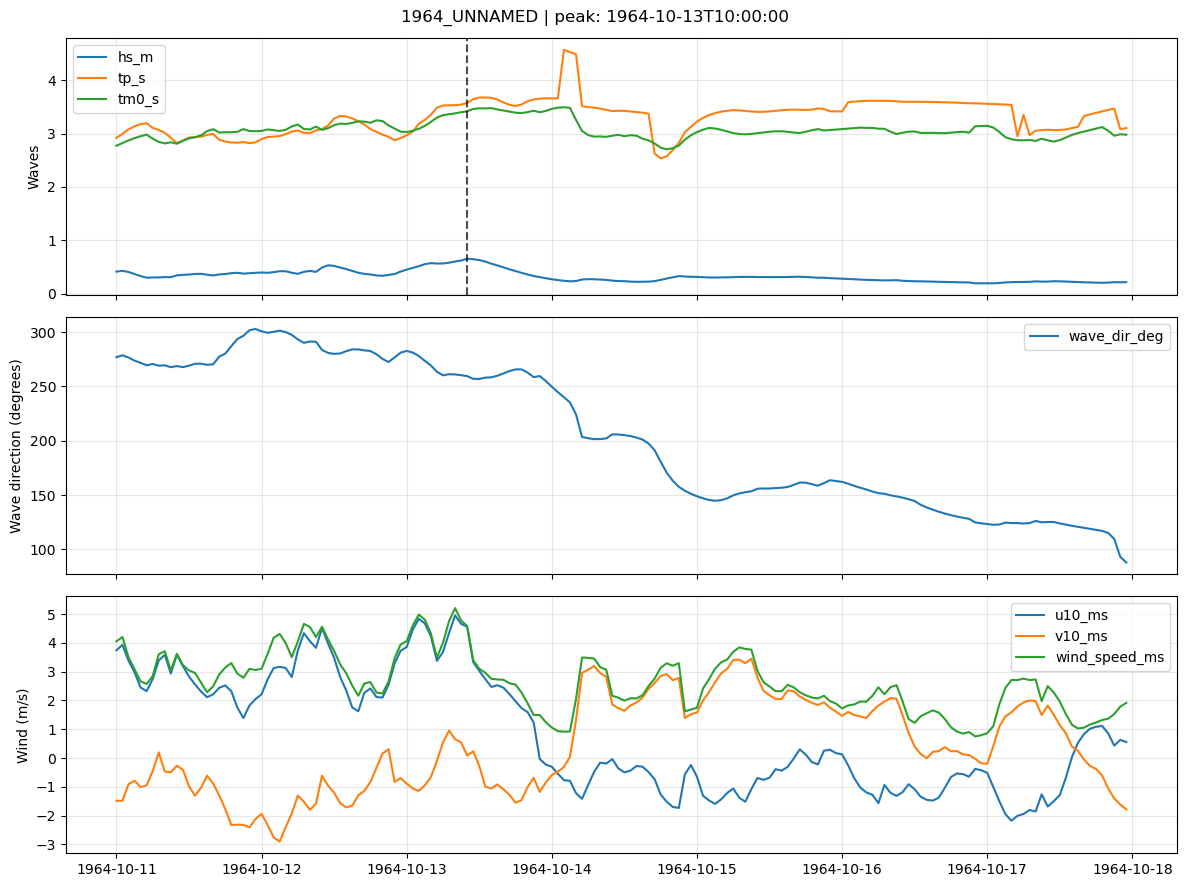

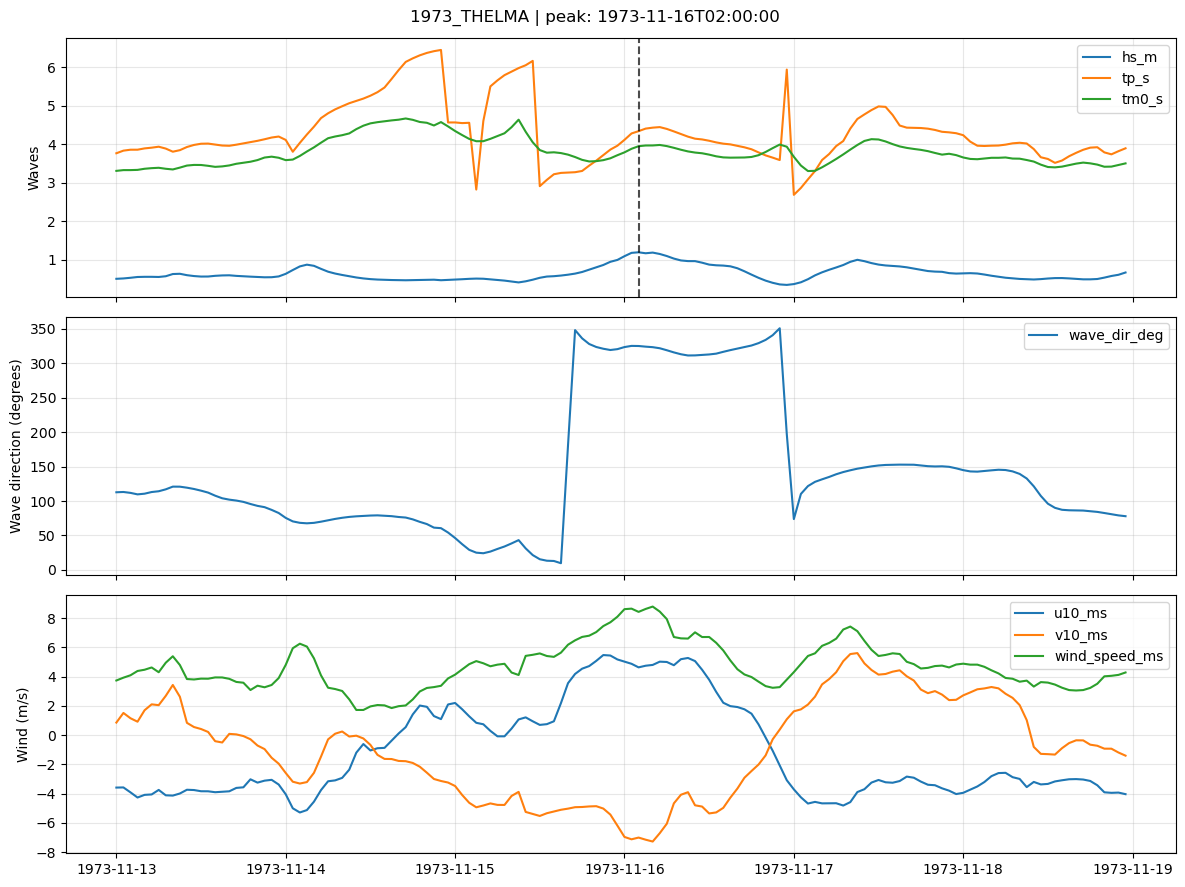

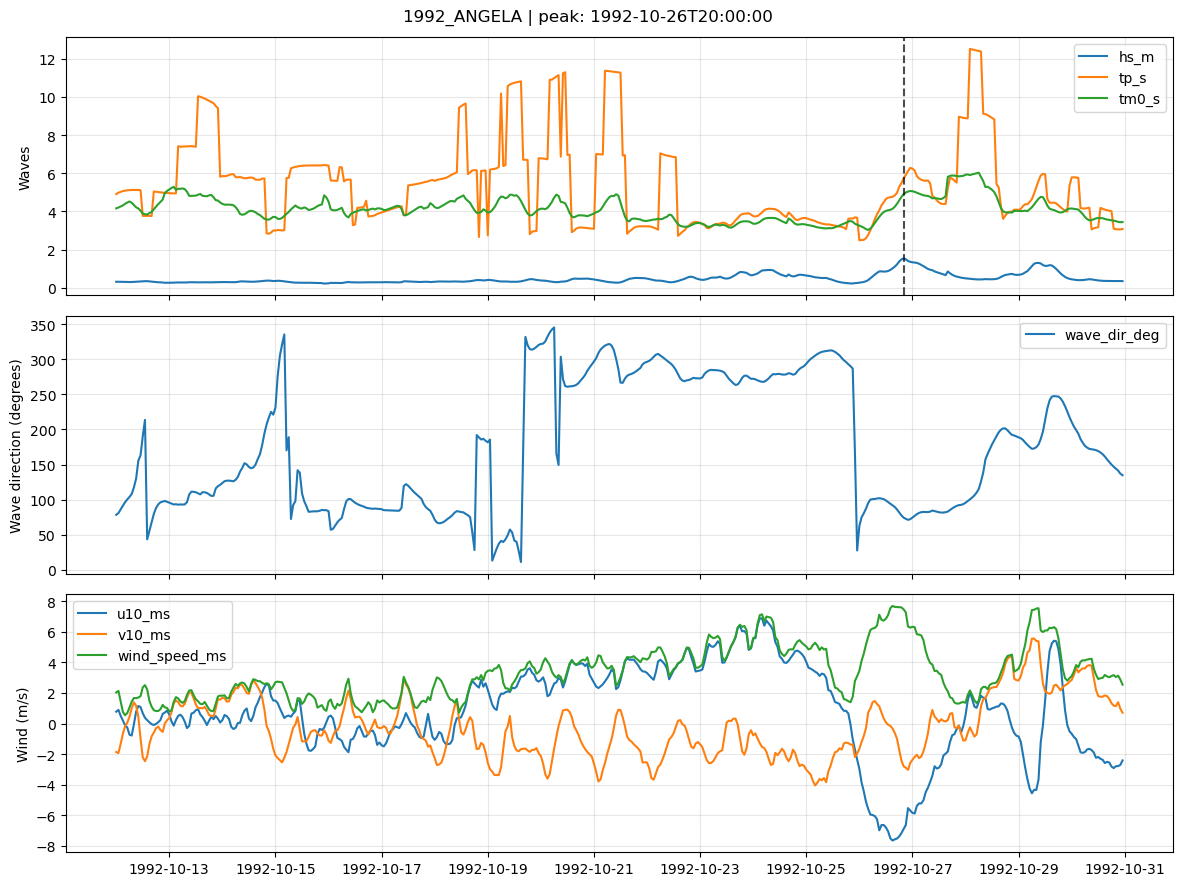

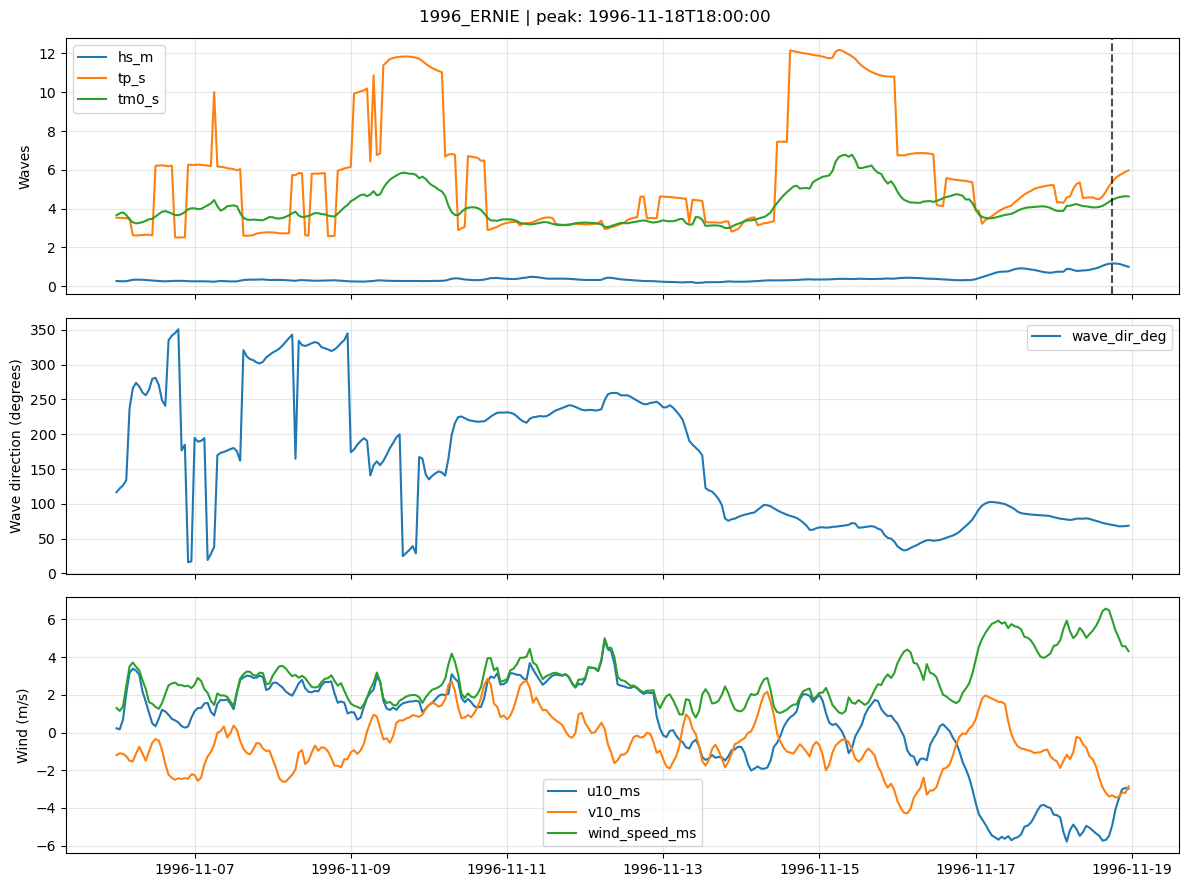

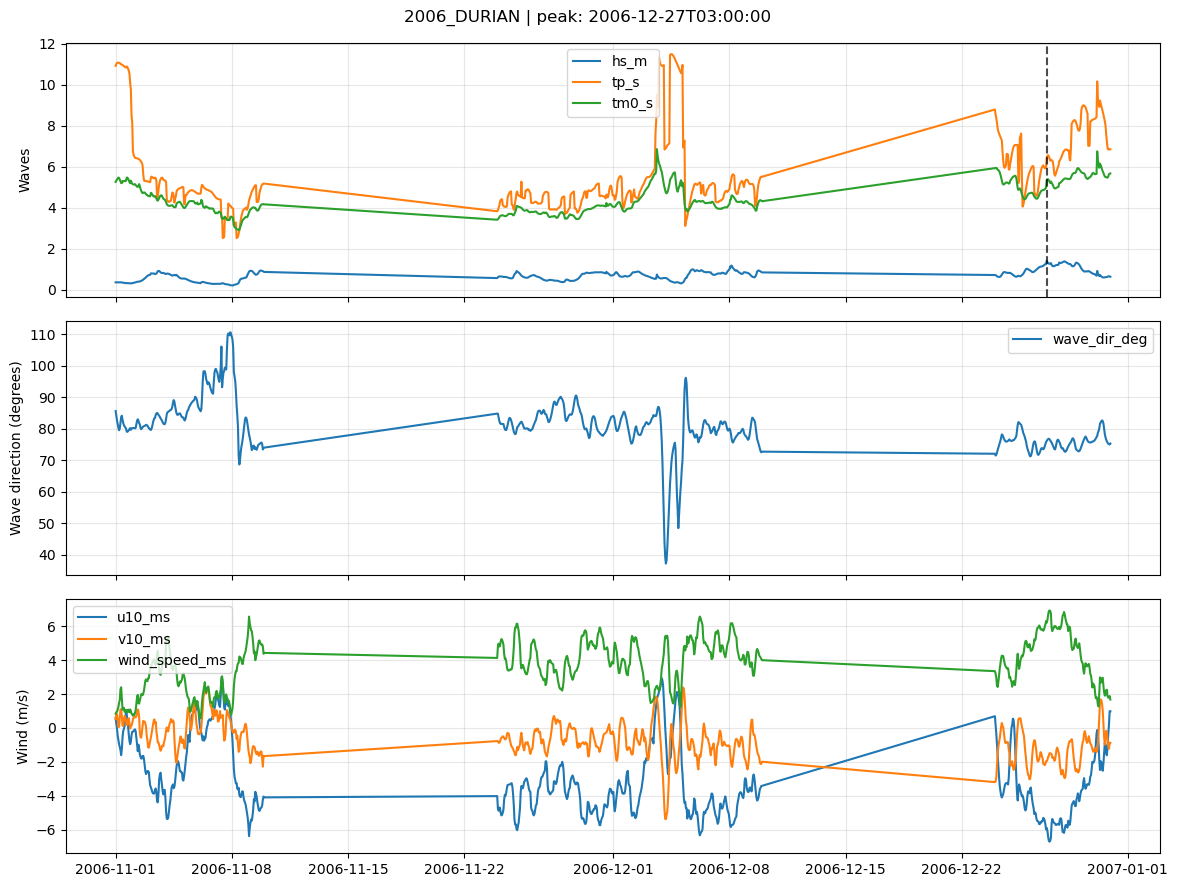

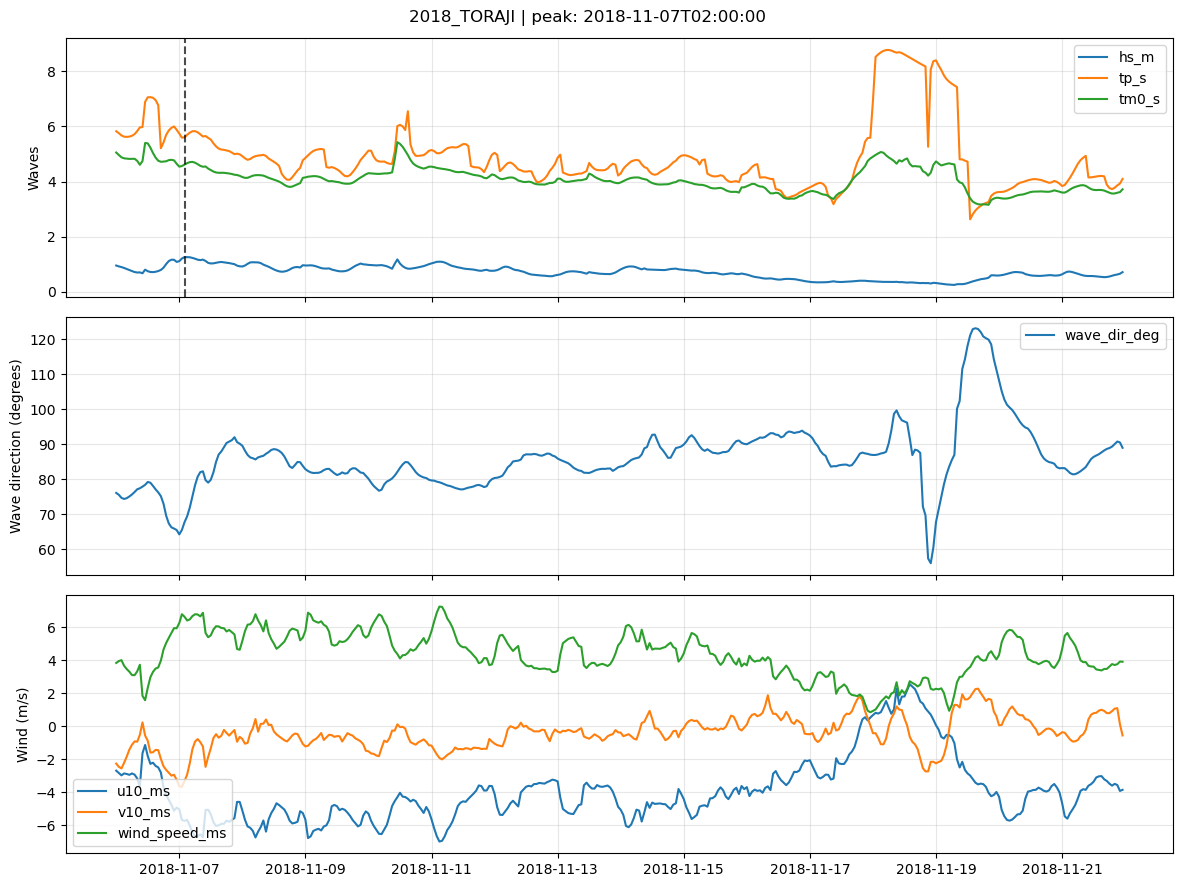

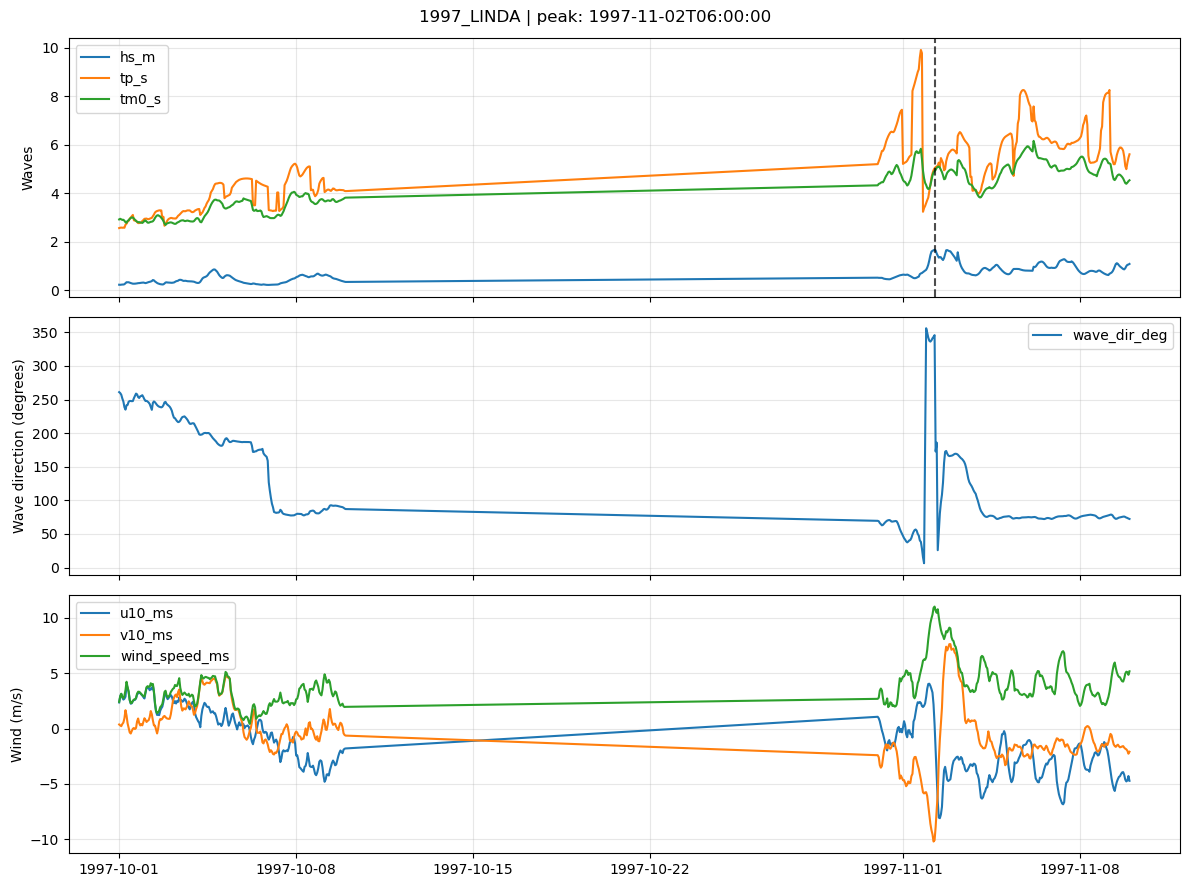

,Peak time,HS spatial mean max (m),HS point max (m),Point max time,Point / mean ratio,Time step (h),HS 6h mean (m),TP 6h median (s),Tm0 6h median (s),Mean wave direction (deg),wave_dir_at_peak_deg,u10 at HS peak (m/s),v10 at HS peak (m/s),Wind speed at HS peak (m/s),u10 6h mean (m/s),v10 6h mean (m/s),Wind speed 6h mean (m/s)
storm,,,,,,,,,,,,,,,,,
1956_UNNAMED,1956-11-12 17:00:00,0.664,0.784,1956-11-12 17:00:00,1.182,1.000,0.647,3.623,3.497,155.046,152.891,-2.701,4.392,5.175,-2.353,4.079,4.802
1962_LUCY,1962-12-31 18:00:00,1.408,1.711,1962-12-31 18:00:00,1.215,1.000,1.370,6.312,4.989,73.505,73.817,-6.690,-2.071,7.025,-6.565,-2.091,6.912
1964_JOAN,1964-11-13 21:00:00,0.714,0.845,1964-11-13 21:00:00,1.184,1.000,0.676,3.444,3.936,15.275,14.752,0.318,-5.619,5.641,0.686,-5.006,5.077
1964_UNNAMED,1964-10-13 10:00:00,0.652,0.777,1964-10-13 10:00:00,1.191,1.000,0.617,3.552,3.399,259.165,259.495,4.557,0.087,4.584,3.943,0.173,4.111
1973_THELMA,1973-11-16 02:00:00,1.194,1.433,1973-11-16 02:00:00,1.200,1.000,1.138,4.181,3.873,323.532,325.221,4.630,-6.998,8.420,4.893,-6.909,8.515
1992_ANGELA,1992-10-26 20:00:00,1.539,1.782,1992-10-26 20:00:00,1.158,1.000,1.414,5.695,4.734,76.600,74.448,-6.898,-2.795,7.469,-6.689,-2.342,7.168
1996_ERNIE,1996-11-18 18:00:00,1.177,1.421,1996-11-18 19:00:00,1.207,1.000,1.134,5.391,4.377,69.762,69.665,-4.902,-3.327,5.964,-4.628,-3.266,5.785
2006_DURIAN,2006-12-27 03:00:00,1.420,1.728,2006-12-28 04:00:00,1.217,1.000,1.297,6.385,5.160,75.902,76.114,-5.902,-1.966,6.222,-6.034,-1.927,6.360
2018_TORAJI,2018-11-07 02:00:00,1.256,1.521,2018-11-07 02:00:00,1.211,1.000,1.198,5.739,4.606,68.547,67.793,-5.741,-3.329,6.648,-5.656,-2.921,6.467


In [ ]:
analysis = {}

for storm_name, variables in storms.items():
    hs = variables['hs_m']
    hs_series = spatial_mean(hs)
    hs_values = np.asarray(hs_series.values, dtype=float)
    times = time_axis(hs_series)
    peak_index = int(np.nanargmax(hs_values))
    peak_time = times[peak_index]
    distance_hours = np.abs((times - peak_time).total_seconds()) / 3600
    window_indices = np.flatnonzero(distance_hours <= window_hours / 2)

    time_steps = np.diff(times.values).astype('timedelta64[s]').astype(float) / 3600
    timestep_hours = float(np.median(time_steps)) if len(time_steps) else np.nan
    spatial_dimensions = [name for name in hs.dims if name != time_dimension(hs)]
    point_max_series = hs.max(dim=spatial_dimensions, skipna=True)
    point_max_values = np.asarray(point_max_series.values, dtype=float)
    point_max_index = int(np.nanargmax(point_max_values))
    point_max_hs = float(point_max_values[point_max_index])
    point_max_time = time_axis(point_max_series)[point_max_index]

    def window_values(name):
        variable = variables.get(name)
        dimension = time_dimension(variable) if variable is not None else None
        return variable.isel({dimension: window_indices}) if dimension else None

    hs_window = window_values('hs_m')
    tp_window = window_values('tp_s')
    tm0_window = window_values('tm0_s')
    direction_window = window_values('wave_dir_deg')
    u_window = window_values('u10_ms')
    v_window = window_values('v10_ms')
    wind_window = window_values('wind_speed_ms')
    u_series = spatial_mean(variables['u10_ms'])
    v_series = spatial_mean(variables['v10_ms'])
    wind_series = spatial_mean(variables['wind_speed_ms'])
    analysis[storm_name] = {
        'peak_time': peak_time,
        'hs_max_m': float(np.nanmax(hs_values)),
        'point_max_hs_m': point_max_hs,
        'point_max_hs_time': point_max_time,
        'point_to_mean_ratio': point_max_hs / float(np.nanmax(hs_values)),
        'timestep_hours': timestep_hours,
        'hs_peak_window_mean_m': value_or_nan(hs_window, np.mean),
        'tp_peak_window_median_s': value_or_nan(tp_window, np.median),
        'tm0_peak_window_median_s': value_or_nan(tm0_window, np.median),
        'wave_dir_mean_deg': vector_mean(direction_window),
        'wave_dir_at_peak_deg': float(np.asarray(spatial_mean(variables['wave_dir_deg']).values)[peak_index]),
        'u10_at_mean_hs_peak_ms': float(u_series.values[peak_index]),
        'v10_at_mean_hs_peak_ms': float(v_series.values[peak_index]),
        'wind_speed_at_mean_hs_peak_ms': float(wind_series.values[peak_index]),
        'u10_peak_window_mean_ms': value_or_nan(u_window, np.mean),
        'v10_peak_window_mean_ms': value_or_nan(v_window, np.mean),
        'wind_speed_peak_window_mean_ms': value_or_nan(wind_window, np.mean)
    }

    figure, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    plot_groups = [
        (('hs_m', 'tp_s', 'tm0_s'), 'Waves'),
        (('wave_dir_deg',), 'Wave direction (degrees)'),
        (('u10_ms', 'v10_ms', 'wind_speed_ms'), 'Wind (m/s)')
    ]
    for axis, (names, title) in zip(axes, plot_groups):
        for name in names:
            if name in variables:
                series = spatial_mean(variables[name])
                axis.plot(time_axis(series), series.values, label=name)
        axis.set_ylabel(title)
        axis.grid(alpha=0.3)
        axis.legend()
    axes[0].axvline(peak_time, color='black', linestyle='--', alpha=0.7)
    figure.suptitle(f'{storm_name} | peak: {peak_time.isoformat()}')
    figure.tight_layout()
    if SAVE:
        figure.savefig(result_dir / f'storm_{storm_name}.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(figure)

results = pd.DataFrame(analysis).T
results.index.name = 'storm'
storm_table = results.rename(columns={
    'peak_time': 'Peak time',
    'hs_max_m': 'HS spatial mean max (m)',
    'point_max_hs_m': 'HS point max (m)',
    'point_max_hs_time': 'Point max time',
    'point_to_mean_ratio': 'Point / mean ratio',
    'timestep_hours': 'Time step (h)',
    'hs_peak_window_mean_m': 'HS 6h mean (m)',
    'tp_peak_window_median_s': 'TP 6h median (s)',
    'tm0_peak_window_median_s': 'Tm0 6h median (s)',
    'wave_dir_mean_deg': 'Mean wave direction (deg)',
    'u10_at_mean_hs_peak_ms': 'u10 at HS peak (m/s)',
    'v10_at_mean_hs_peak_ms': 'v10 at HS peak (m/s)',
    'wind_speed_at_mean_hs_peak_ms': 'Wind speed at HS peak (m/s)',
    'u10_peak_window_mean_ms': 'u10 6h mean (m/s)',
    'v10_peak_window_mean_ms': 'v10 6h mean (m/s)',
    'wind_speed_peak_window_mean_ms': 'Wind speed 6h mean (m/s)'
})
if SAVE:
    storm_table.to_csv(result_dir / 'storm_historical_conditions.csv')
display(styled_table(storm_table, 'Historical storm conditions and HS plausibility check'))

# Cell 3: derive design storm conditions
The notebook combines the in-memory storm results into three Delft3D scenarios:

Realistic peak: median of the observed six-hour storm-peak HS values and median peak-window TP; duration 6 hours.
Conservative: 99th percentile of all selected offshore HS and TP values; duration 6 hours.
Extreme: largest observed spatially averaged HS, with the TP associated with that storm; duration 3 hours.
The formatted design table contains HS, TP, Tm0, mean wave direction, u10, v10, wind speed, duration and the method basis. It is displayed in the notebook and is not exported to a file.

In [5]:
def all_values(name):
    values = [finite_values(variables[name]) for variables in storms.values() if name in variables]
    values = [value for value in values if len(value)]
    return np.concatenate(values) if values else np.array([], dtype=float)


def percentile(name, value):
    values = all_values(name)
    return float(np.percentile(values, value)) if len(values) else np.nan


def value_at_time(storm_name, name, target_time):
    variable = storms[storm_name].get(name)
    if variable is None:
        return np.nan
    series = spatial_mean(variable)
    index = int(np.argmin(np.abs(time_axis(series) - pd.Timestamp(target_time))))
    return float(series.values[index])


hs_peaks = results['hs_peak_window_mean_m'].to_numpy(dtype=float)
tp_peaks = results['tp_peak_window_median_s'].to_numpy(dtype=float)
tm0_peaks = results['tm0_peak_window_median_s'].to_numpy(dtype=float)
max_point_storm = results['point_max_hs_m'].idxmax()
max_point_hs = float(results.loc[max_point_storm, 'point_max_hs_m'])
max_point_time = results.loc[max_point_storm, 'point_max_hs_time']

realistic = {
    'scenario': 'Realistic peak',
    'hs_m': float(np.nanmedian(hs_peaks)),
    'tp_s': float(np.nanmedian(tp_peaks)),
    'tm0_s': value_or_nan(tm0_peaks, np.median),
    'wave_dir_mean_deg': vector_mean(results['wave_dir_mean_deg']),
    'u10_ms': value_or_nan(results['u10_peak_window_mean_ms'], np.median),
    'v10_ms': value_or_nan(results['v10_peak_window_mean_ms'], np.median),
    'wind_speed_ms': value_or_nan(results['wind_speed_peak_window_mean_ms'], np.median),
    'duration_hours': window_hours,
    'basis': 'Median of the observed six-hour spatial-mean peak windows.'
}
conservative = {
    'scenario': 'Conservative',
    'hs_m': percentile('hs_m', 99),
    'tp_s': percentile('tp_s', 99),
    'tm0_s': percentile('tm0_s', 99),
    'wave_dir_mean_deg': vector_mean(all_values('wave_dir_deg')),
    'u10_ms': percentile('u10_ms', 99),
    'v10_ms': percentile('v10_ms', 99),
    'wind_speed_ms': percentile('wind_speed_ms', 99),
    'duration_hours': window_hours,
    'basis': '99th percentile of scalar offshore values; circular mean direction.'
}
extreme = {
    'scenario': 'Extreme point peak',
    'hs_m': max_point_hs,
    'tp_s': value_at_time(max_point_storm, 'tp_s', max_point_time),
    'tm0_s': value_at_time(max_point_storm, 'tm0_s', max_point_time),
    'wave_dir_mean_deg': value_at_time(max_point_storm, 'wave_dir_deg', max_point_time),
    'u10_ms': value_at_time(max_point_storm, 'u10_ms', max_point_time),
    'v10_ms': value_at_time(max_point_storm, 'v10_ms', max_point_time),
    'wind_speed_ms': value_at_time(max_point_storm, 'wind_speed_ms', max_point_time),
    'duration_hours': 3,
    'basis': f'Point maximum HS in {max_point_storm} at {max_point_time}; short-duration upper bound.'
}

design_storms = pd.DataFrame([realistic, conservative, extreme])
design_table = design_storms.rename(columns={
    'scenario': 'Scenario',
    'hs_m': 'HS (m)',
    'tp_s': 'TP (s)',
    'tm0_s': 'Tm0 (s)',
    'wave_dir_mean_deg': 'Mean wave direction (deg)',
    'u10_ms': 'u10 (m/s)',
    'v10_ms': 'v10 (m/s)',
    'wind_speed_ms': 'Wind speed (m/s)',
    'duration_hours': 'Duration (h)',
    'basis': 'Basis'
}).set_index('Scenario')
print(f'Design location: {target_lat:.6f} N, {target_lon:.6f} E')
display(styled_table(design_table, 'Delft3D design storm conditions'))
print('Use Realistic peak for a short Delft3D run; retain Conservative as a check.')

Design location: 9.259944 N, 105.956639 E


,HS (m),TP (s),Tm0 (s),Mean wave direction (deg),u10 (m/s),v10 (m/s),Wind speed (m/s),Duration (h),Basis
Scenario,,,,,,,,,
Realistic peak,1.168,5.129,4.491,50.099,-3.490,-2.632,6.414,6,Median of the observed six-hour spatial-mean peak windows.
Conservative,1.591,11.864,6.466,82.696,5.868,5.335,10.028,6,99th percentile of scalar offshore values; circular mean direction.
Extreme point peak,2.057,5.024,4.915,345.841,0.358,-10.070,11.006,3,Point maximum HS in 1997_LINDA at 1997-11-02 06:00:00; short-duration upper bound.


Use Realistic peak for a short Delft3D run; retain Conservative as a check.


In [ ]:
# Cell 6 - Use IBTrACS winds in the Delft3D design conditions
ibtracs_path = data_dir / 'IBTrACS.WP.v04r01_20260728.nc'
if not ibtracs_path.exists():
    raise FileNotFoundError(f'IBTrACS file not found: {ibtracs_path}')

ibtracs = xr.open_dataset(ibtracs_path, engine='h5netcdf', decode_times=False)
print('IBTrACS wind units:', ibtracs['wmo_wind'].attrs.get('units'), ibtracs['usa_wind'].attrs.get('units'))

storm_names = [
    '1956_UNNAMED', '1962_LUCY', '1964_JOAN', '1964_UNNAMED',
    '1973_THELMA', '1992_ANGELA', '1996_ERNIE', '1997_LINDA',
    '2006_DURIAN', '2018_TORAJI'
 ]
ibtracs_wind = {}
comparison_rows = []


def decode_name(value):
    return value.decode().strip() if isinstance(value, bytes) else str(value).strip()


def ibtracs_datetime(values):
    values = np.asarray(values)
    if np.issubdtype(values.dtype, np.datetime64):
        return pd.to_datetime(values).round('s')
    unit, origin = ibtracs['time'].attrs['units'].split(' since ', 1)
    unit = {'hours': 'h', 'days': 'D', 'minutes': 'm', 'seconds': 's'}[unit]
    numeric = pd.to_numeric(values.ravel(), errors='coerce')
    return pd.DatetimeIndex(pd.Timestamp(origin) + pd.to_timedelta(numeric, unit=unit)).round('s')


def track_times(storm_index):
    times = ibtracs_datetime(ibtracs['time'].isel(storm=storm_index).values)
    valid = (times >= pd.Timestamp('1900-01-01')) & (times <= pd.Timestamp('2030-01-01'))
    return times, valid


def wind_to_ms(variable_name, storm_index):
    variable = ibtracs[variable_name]
    values = np.asarray(variable.isel(storm=storm_index).values, dtype=float)
    units = str(variable.attrs.get('units', '')).lower()
    if 'm/s' in units or 'm s' in units or 'ms-1' in units:
        return values
    return values * 0.514444


def wind_values_for_track(storm_index):
    wmo_ms = wind_to_ms('wmo_wind', storm_index)
    usa_ms = wind_to_ms('usa_wind', storm_index)
    return np.where(np.isfinite(wmo_ms) & (wmo_ms >= 0), wmo_ms, np.where(np.isfinite(usa_ms) & (usa_ms >= 0), usa_ms, np.nan))


for storm_name in storm_names:
    era5_peak = pd.Timestamp(results.loc[storm_name, 'peak_time'])
    wanted_name = storm_name.split('_', 1)[-1].upper()
    named_candidates = [
        index for index, value in enumerate(ibtracs['name'].values)
        if decode_name(value).upper() == wanted_name
    ]
    candidates = named_candidates or list(range(ibtracs.sizes['storm']))
    best_track = None
    best_record = None
    best_distance = np.inf

    for storm_index in candidates:
        ib_times, valid = track_times(storm_index)
        if not valid.any():
            continue
        distances = np.asarray(np.abs((ib_times - era5_peak).total_seconds()), dtype=float)
        distances[~valid] = np.nan
        record_index = int(np.nanargmin(distances))
        if distances[record_index] < best_distance:
            best_track, best_record, best_distance = storm_index, record_index, distances[record_index]

    row = {
        'storm': storm_name,
        'ERA5 wind at HS peak (m/s)': results.loc[storm_name, 'wind_speed_at_mean_hs_peak_ms'],
        'IBTrACS wind at ERA5 HS peak (m/s)': np.nan,
        'IBTrACS maximum wind (m/s)': np.nan,
        'IBTrACS peak record time': pd.NaT,
        'IBTrACS maximum wind time': pd.NaT,
        'source': 'not found'
    }
    if best_track is None:
        ibtracs_wind[storm_name] = np.nan
        comparison_rows.append(row)
        continue

    ib_times, valid = track_times(best_track)
    track_winds = wind_values_for_track(best_track)
    track_winds[~valid] = np.nan
    selected_wind = track_winds[best_record]
    maximum_index = int(np.nanargmax(track_winds)) if np.isfinite(track_winds).any() else None
    maximum_wind = track_winds[maximum_index] if maximum_index is not None else np.nan
    wmo_at_peak = float(ibtracs['wmo_wind'].isel(storm=best_track, date_time=best_record))
    usa_at_peak = float(ibtracs['usa_wind'].isel(storm=best_track, date_time=best_record))
    if np.isfinite(wmo_at_peak) and wmo_at_peak >= 0:
        source = 'wmo_wind converted to m/s'
    elif np.isfinite(usa_at_peak) and usa_at_peak >= 0:
        source = 'usa_wind converted from knots to m/s'
    else:
        source = 'missing'

    ibtracs_wind[storm_name] = selected_wind
    row.update({
        'IBTrACS wind at ERA5 HS peak (m/s)': selected_wind,
        'IBTrACS maximum wind (m/s)': maximum_wind,
        'IBTrACS peak record time': ib_times[best_record],
        'IBTrACS maximum wind time': ib_times[maximum_index] if maximum_index is not None else pd.NaT,
        'source': source
    })
    comparison_rows.append(row)

ibtracs_comparison = pd.DataFrame(comparison_rows).set_index('storm')
display(styled_table(ibtracs_comparison, 'ERA5 peak wind versus IBTrACS track winds'))

# Replace the ERA5 wind values in the Delft3D design scenarios with IBTrACS winds at the ERA5 HS peak.
peak_winds = pd.Series(ibtracs_wind, dtype=float).dropna()
if peak_winds.empty:
    raise ValueError('No valid IBTrACS winds were found at the ERA5 HS peaks.')

ibtracs_design_winds = {
    'Realistic peak': float(peak_winds.median()),
    'Conservative': float(np.percentile(peak_winds, 99)),
    'Extreme point peak': float(ibtracs_wind[max_point_storm])
}

for row in design_storms.to_dict('records'):
    wind_speed = ibtracs_design_winds[row['scenario']]
    era5_speed = np.hypot(row['u10_ms'], row['v10_ms'])
    if not np.isfinite(era5_speed) or era5_speed == 0:
        raise ValueError(f'Cannot preserve wind direction for {row["scenario"]}: ERA5 components are invalid.')
    scale = wind_speed / era5_speed
    row['u10_ms'] *= scale
    row['v10_ms'] *= scale
    row['wind_speed_ms'] = wind_speed
    row['basis'] += ' Wind speed from IBTrACS at the ERA5 HS peak; ERA5 direction retained for u10/v10 decomposition.'

design_storms = pd.DataFrame(design_storms.to_dict('records'))
design_table = design_storms.rename(columns={
    'scenario': 'Scenario',
    'hs_m': 'HS (m)',
    'tp_s': 'TP (s)',
    'tm0_s': 'Tm0 (s)',
    'wave_dir_mean_deg': 'Mean wave direction (deg)',
    'u10_ms': 'u10 (m/s)',
    'v10_ms': 'v10 (m/s)',
    'wind_speed_ms': 'Wind speed (m/s)',
    'duration_hours': 'Duration (h)',
    'basis': 'Basis'
}).set_index('Scenario')
if SAVE:
    ibtracs_comparison.to_csv(result_dir / 'storm_era5_vs_ibtracs_wind.csv')
display(styled_table(design_table, 'Delft3D design storm conditions with IBTrACS winds at ERA5 HS peaks'))
print('Delft3D design wind speeds now come from IBTrACS at the ERA5 HS peaks.')

IBTrACS wind units: kts kts


,ERA5 wind at HS peak (m/s),IBTrACS wind at ERA5 HS peak (m/s),IBTrACS maximum wind (m/s),IBTrACS peak record time,IBTrACS maximum wind time,source
storm,,,,,,
1956_UNNAMED,5.175,n/a,n/a,1956-11-12 18:00:00,n/a,missing
1962_LUCY,7.025,10.289,51.444,1962-12-01 18:00:00,1962-11-29 00:00:00,usa_wind converted from knots to m/s
1964_JOAN,5.641,n/a,36.011,1964-11-13 21:00:00,1964-11-08 12:00:00,missing
1964_UNNAMED,4.584,n/a,n/a,1964-10-13 09:00:00,n/a,missing
1973_THELMA,8.420,16.977,28.294,1973-11-16 03:00:00,1973-11-15 12:00:00,usa_wind converted from knots to m/s
1992_ANGELA,7.469,15.433,46.300,1992-10-26 21:00:00,1992-10-19 09:00:00,usa_wind converted from knots to m/s
1996_ERNIE,5.964,10.289,23.150,1996-11-18 06:00:00,1996-11-10 03:00:00,usa_wind converted from knots to m/s
1997_LINDA,11.006,25.722,33.439,1997-11-02 06:00:00,1997-11-02 21:00:00,wmo_wind converted to m/s
2006_DURIAN,6.222,7.717,68.421,2006-12-09 18:00:00,2006-11-29 15:00:00,usa_wind converted from knots to m/s


,HS (m),TP (s),Tm0 (s),Mean wave direction (deg),u10 (m/s),v10 (m/s),Wind speed (m/s),Duration (h),Basis
Scenario,,,,,,,,,
Realistic peak,1.168,5.129,4.491,50.099,-8.215,-6.194,10.289,6,Median of the observed six-hour spatial-mean peak windows. Wind speed from IBTrACS; ERA5 direction retained for u10/v10 decomposition.
Conservative,1.591,11.864,6.466,82.696,49.745,45.229,67.233,6,99th percentile of scalar offshore values; circular mean direction. Wind speed from IBTrACS; ERA5 direction retained for u10/v10 decomposition.
Extreme point peak,2.057,5.024,4.915,345.841,1.188,-33.418,33.439,3,Point maximum HS in 1997_LINDA at 1997-11-02 06:00:00; short-duration upper bound. Wind speed from IBTrACS; ERA5 direction retained for u10/v10 decomposition.


Delft3D design wind speeds now come from IBTrACS at the ERA5 HS peaks.


In [ ]:
# Apply the IBTrACS winds at the ERA5 HS peak to the final Delft3D design table.
for index, row in design_storms.iterrows():
    wind_speed = ibtracs_design_winds[row['scenario']]
    era5_speed = np.hypot(row['u10_ms'], row['v10_ms'])
    if not np.isfinite(era5_speed) or era5_speed == 0:
        raise ValueError(f'Cannot preserve wind direction for {row["scenario"]}: ERA5 components are invalid.')
    scale = wind_speed / era5_speed
    design_storms.loc[index, 'u10_ms'] = row['u10_ms'] * scale
    design_storms.loc[index, 'v10_ms'] = row['v10_ms'] * scale
    design_storms.loc[index, 'wind_speed_ms'] = wind_speed
    design_storms.loc[index, 'basis'] = row['basis'] + ' Wind speed from IBTrACS at the ERA5 HS peak; ERA5 direction retained for u10/v10 decomposition.'

design_table = design_storms.rename(columns={
    'scenario': 'Scenario',
    'hs_m': 'HS (m)',
    'tp_s': 'TP (s)',
    'tm0_s': 'Tm0 (s)',
    'wave_dir_mean_deg': 'Mean wave direction (deg)',
    'u10_ms': 'u10 (m/s)',
    'v10_ms': 'v10 (m/s)',
    'wind_speed_ms': 'Wind speed (m/s)',
    'duration_hours': 'Duration (h)',
    'basis': 'Basis'
}).set_index('Scenario')
design_speed_check = np.hypot(design_storms['u10_ms'], design_storms['v10_ms'])
assert np.allclose(design_speed_check, design_storms['wind_speed_ms'])
display(styled_table(design_table, 'Delft3D design storm conditions with IBTrACS winds at ERA5 HS peaks'))
if SAVE:
    design_table.to_csv(result_dir / 'storm_design_conditions.csv')
print('Delft3D design wind speeds use IBTrACS at the ERA5 HS peaks, not IBTrACS maximum winds.')

,HS (m),TP (s),Tm0 (s),Mean wave direction (deg),u10 (m/s),v10 (m/s),Wind speed (m/s),Duration (h),Basis
Scenario,,,,,,,,,
Realistic peak,1.168,5.129,4.491,50.099,-8.215,-6.194,10.289,6,Median of the observed six-hour spatial-mean peak windows. Wind speed from IBTrACS; ERA5 direction retained for u10/v10 decomposition. Wind speed from IBTrACS at the ERA5 HS peak; ERA5 direction retained for u10/v10 decomposition.
Conservative,1.591,11.864,6.466,82.696,18.643,16.951,25.197,6,99th percentile of scalar offshore values; circular mean direction. Wind speed from IBTrACS; ERA5 direction retained for u10/v10 decomposition. Wind speed from IBTrACS at the ERA5 HS peak; ERA5 direction retained for u10/v10 decomposition.
Extreme point peak,2.057,5.024,4.915,345.841,0.914,-25.706,25.722,3,Point maximum HS in 1997_LINDA at 1997-11-02 06:00:00; short-duration upper bound. Wind speed from IBTrACS; ERA5 direction retained for u10/v10 decomposition. Wind speed from IBTrACS at the ERA5 HS peak; ERA5 direction retained for u10/v10 decomposition.


Delft3D design wind speeds use IBTrACS at the ERA5 HS peaks, not IBTrACS maximum winds.
